# History explorer

Browse an organic history: pick a map field and a kept epoch, show the planet events since the previous epoch, and hover over the map for the values of the cell under the cursor. The timeline below marks the epoch.

Needs the `explore` extra (`pip install -e ".[explore]"`). Hover needs the ipympl backend, switched on by `%matplotlib widget`; without it the maps redraw as images.

In [1]:
%matplotlib widget
from pathlib import Path

import cartopy.crs as ccrs
import matplotlib.pyplot as plt

from worldgen import generate_world, load_spec, load_world
from worldgen.culture import CultureSpec, apply_culture
from worldgen.render import HistoryExplorer

Load a saved world with an organic history, or build one from the Earth example (a few minutes at preview resolution).

In [5]:
SAVED = Path("../output/earth_history")       # a world saved with an organic history, if there is one

if SAVED.exists():
    world = load_world(SAVED)
else:
    spec = load_spec("../examples/earth.yaml")
    culture = CultureSpec.model_validate({
        "history": {"start_years_ago": 10000, "epochs": [8000, 7000, 6000, 5000, 4000, 3000, 2000, 1900, 1800, 1700, 1600, 1500, 1400, 1300, 1200,
        1100, 1000, 900, 800, 700, 600, 500, 400, 350, 300, 275, 250, 225,
        200, 175, 150, 125, 100, 75, 50, 25, 10, 5, 1]},
        "cultures": [{"name": "Oru", "mode": "organic"}]})
    world = apply_culture(generate_world(spec, resolution="standard"), culture)

In [6]:
explorer = HistoryExplorer(world)
explorer.widget()

The same views without the widget: one field at one epoch, and the values of one cell.

44.8°, 9.5°
elevation 1,493 m
boreal forest, Köppen Dwa
0.00525 people/km², mostly Oru
state: Yliwkè
farming / pack and boat / oral
no herds
fresh water 0.43, arable 0.50, access 0.00, resources 0.55, climate 0.73, defensibility 0.00


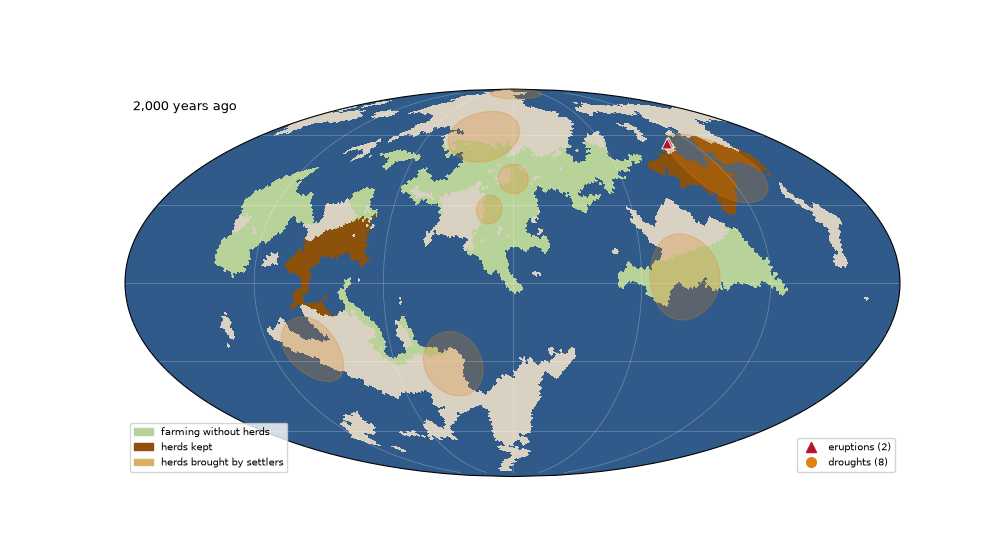

In [4]:
fig = plt.figure(figsize=(10, 5.6))
explorer.draw(fig, "livestock", explorer.dates[len(explorer.dates) // 2])
x, y = explorer.proj.transform_point(10.0, 45.0, ccrs.PlateCarree())      # longitude, latitude
print(explorer.describe(explorer.cell_at(x, y), 0.0))